# 01 — Exploration (EDA) et nettoyage

**Projet** : classification des candidats selon leur employabilité (apprentissage automatique classique).

**Dataset** : *70k+ Job Applicants Data (Human Resource)* — 73 462 candidats, cible binaire `Employed`.

Sortie de ce notebook : `data/processed/applicants_clean.csv`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/raw/stackoverflow_full.csv')
df.shape

(73462, 15)

## 1. Structure et typage

In [2]:
df.head()

,Unnamed: 0,Age,Accessibility,EdLevel,Employment,Gender,MentalHealth,MainBranch,YearsCode,YearsCodePro,Country,PreviousSalary,HaveWorkedWith,ComputerSkills,Employed
0,0,<35,No,Master,1,Man,No,Dev,7,4,Sweden,51552.0,C++;Python;Git;PostgreSQL,4,0
1,1,<35,No,Undergraduate,1,Man,No,Dev,12,5,Spain,46482.0,Bash/Shell;HTML/CSS;JavaScript;Node.js;SQL;Typ...,12,1
2,2,<35,No,Master,1,Man,No,Dev,15,6,Germany,77290.0,C;C++;Java;Perl;Ruby;Git;Ruby on Rails,7,0
3,3,<35,No,Undergraduate,1,Man,No,Dev,9,6,Canada,46135.0,Bash/Shell;HTML/CSS;JavaScript;PHP;Ruby;SQL;Gi...,13,0
4,4,>35,No,PhD,0,Man,No,NotDev,40,30,Singapore,160932.0,C++;Python,2,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 73462 entries, 0 to 73461
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      73462 non-null  int64  
 1   Age             73462 non-null  str    
 2   Accessibility   73462 non-null  str    
 3   EdLevel         73462 non-null  str    
 4   Employment      73462 non-null  int64  
 5   Gender          73462 non-null  str    
 6   MentalHealth    73462 non-null  str    
 7   MainBranch      73462 non-null  str    
 8   YearsCode       73462 non-null  int64  
 9   YearsCodePro    73462 non-null  int64  
 10  Country         73462 non-null  str    
 11  PreviousSalary  73462 non-null  float64
 12  HaveWorkedWith  73399 non-null  str    
 13  ComputerSkills  73462 non-null  int64  
 14  Employed        73462 non-null  int64  
dtypes: float64(1), int64(6), str(8)
memory usage: 18.6 MB


- `Unnamed: 0` est un simple index exporté -> à supprimer.
- `Employed` est la **cible** (1 = employé, 0 = non employé).
- `HaveWorkedWith` est une liste de technologies séparées par `;` (variable *multi-valuée*).
- `ComputerSkills` semble être le nombre de technologies de `HaveWorkedWith` (vérifié plus bas).
- `Employment` est un indicateur 0/1 dont la définition n'est pas documentée : à traiter avec prudence.

## 2. Valeurs manquantes et doublons

In [4]:
print('Doublons (hors index) :', df.drop(columns='Unnamed: 0').duplicated().sum())
df.isna().sum()[lambda s: s > 0]

Doublons (hors index) : 4


HaveWorkedWith    63
dtype: int64

## 3. Statistiques descriptives

In [5]:
num_cols = ['YearsCode', 'YearsCodePro', 'PreviousSalary', 'ComputerSkills']
df[num_cols + ['Employment']].describe().T

,count,mean,std,min,25%,50%,75%,max
YearsCode,73462.0,14.218902,9.405172,0.0,7.0,12.0,20.0,50.0
YearsCodePro,73462.0,9.098377,7.960201,0.0,3.0,7.0,12.0,50.0
PreviousSalary,73462.0,67750.260611,49488.142118,1.0,28839.0,57588.0,95979.0,224000.0
ComputerSkills,73462.0,13.428221,7.057835,0.0,8.0,13.0,17.0,107.0
Employment,73462.0,0.883096,0.321308,0.0,1.0,1.0,1.0,1.0


In [6]:
cat_cols = ['Age', 'Accessibility', 'EdLevel', 'Gender', 'MentalHealth', 'MainBranch']
for c in cat_cols:
    print(df[c].value_counts(normalize=True).round(3).to_dict())
print('Pays distincts :', df['Country'].nunique())
df['Country'].value_counts().head(10)

{'<35': 0.651, '>35': 0.349}
{'No': 0.971, 'Yes': 0.029}
{'Undergraduate': 0.509, 'Master': 0.257, 'Other': 0.148, 'NoHigherEd': 0.05, 'PhD': 0.036}
{'Man': 0.933, 'Woman': 0.048, 'NonBinary': 0.019}
{'No': 0.775, 'Yes': 0.225}
{'Dev': 0.917, 'NotDev': 0.083}
Pays distincts : 172


Country
United States of America                                14696
Germany                                                  5395
India                                                    5360
United Kingdom of Great Britain and Northern Ireland     4688
Canada                                                   2779
France                                                   2650
Brazil                                                   2624
Poland                                                   1922
Netherlands                                              1761
Spain                                                    1712
Name: count, dtype: int64

## 4. Contrôles de cohérence

In [7]:
n_techs = df['HaveWorkedWith'].fillna('').apply(lambda s: len([t for t in s.split(';') if t]))
print('ComputerSkills == nombre de technologies de HaveWorkedWith :', (n_techs == df['ComputerSkills']).mean())
print('Lignes avec YearsCodePro > YearsCode (incohérent) :', (df['YearsCodePro'] > df['YearsCode']).sum())
print('Lignes avec HaveWorkedWith manquant :', df['HaveWorkedWith'].isna().sum(),
      '| ComputerSkills de ces lignes :', df.loc[df['HaveWorkedWith'].isna(), 'ComputerSkills'].unique())

ComputerSkills == nombre de technologies de HaveWorkedWith : 1.0
Lignes avec YearsCodePro > YearsCode (incohérent) : 588
Lignes avec HaveWorkedWith manquant : 63 | ComputerSkills de ces lignes : [0]


## 5. Variable cible

Employed
1    0.5362
0    0.4638
Name: proportion, dtype: float64


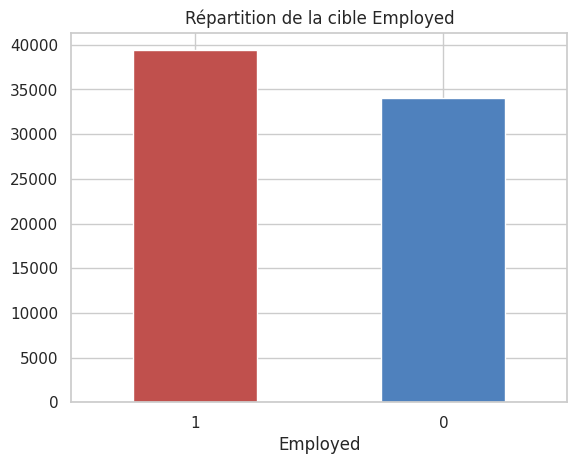

In [8]:
print(df['Employed'].value_counts(normalize=True).round(4))
df['Employed'].value_counts().plot.bar(color=['#c0504d', '#4f81bd'])
plt.title('Répartition de la cible Employed'); plt.xticks(rotation=0); plt.show()

Les classes sont **quasi équilibrées** (≈ 54 % / 46 %) : contrairement à un jeu très déséquilibré, l'accuracy reste ici informative, mais on suit quand même le F1 des deux classes.

## 6. Distributions et valeurs aberrantes (règle de Tukey / IQR)

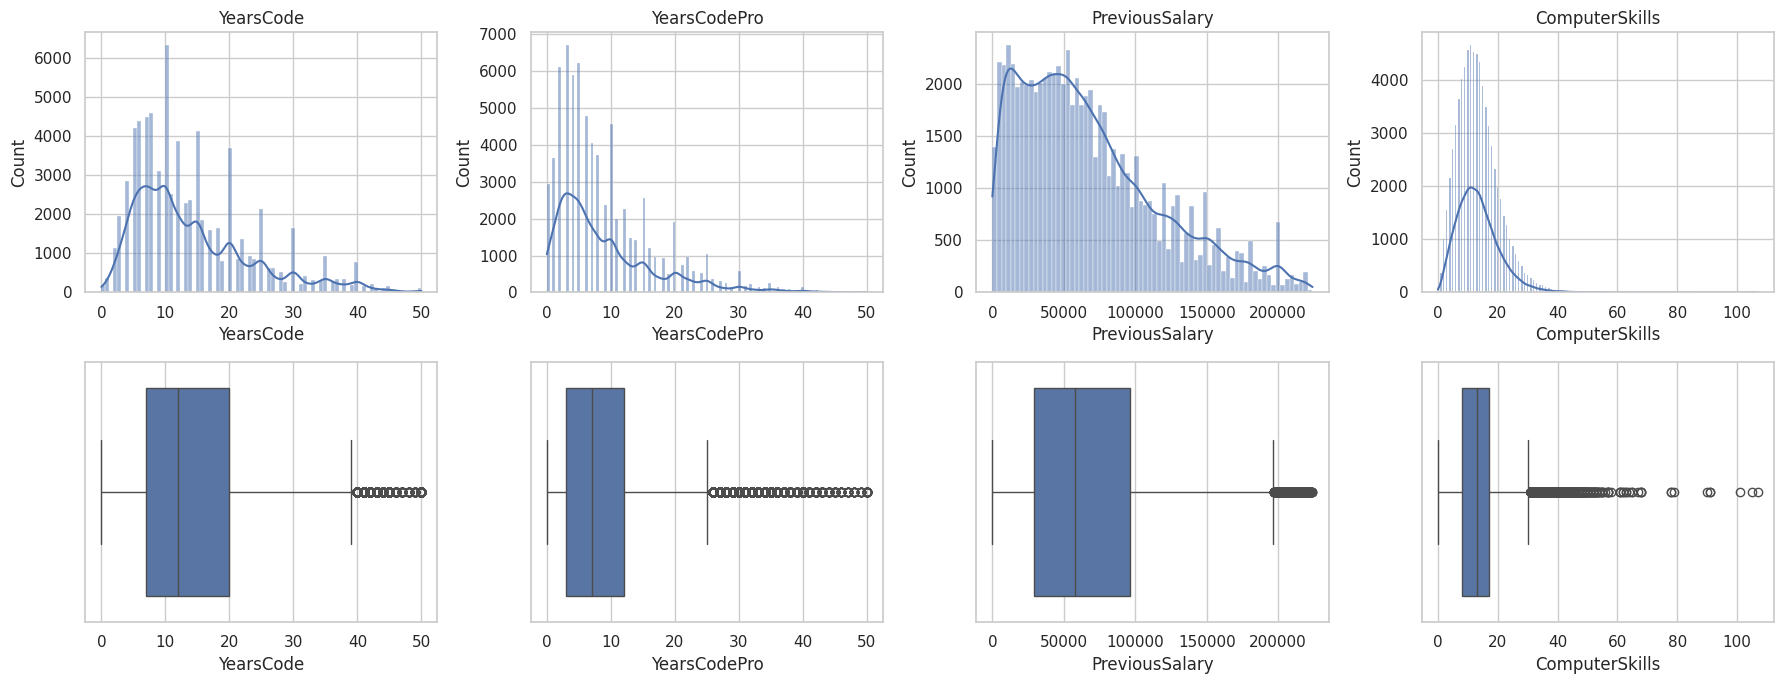

,variable,nb_outliers,%
0,YearsCode,1809,2.46
1,YearsCodePro,3353,4.56
2,PreviousSalary,1479,2.01
3,ComputerSkills,1633,2.22


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i]); axes[0, i].set_title(c)
    sns.boxplot(x=df[c], ax=axes[1, i])
plt.tight_layout(); plt.show()

rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append((c, n_out, round(100 * n_out / len(df), 2)))
pd.DataFrame(rows, columns=['variable', 'nb_outliers', '%'])

Les valeurs extrêmes (salaires élevés, nombre élevé de technologies) sont plausibles : on **les conserve** et on atténue l'asymétrie du salaire par une transformation `log1p` au prétraitement.

## 7. Taux d'employabilité selon les variables catégorielles

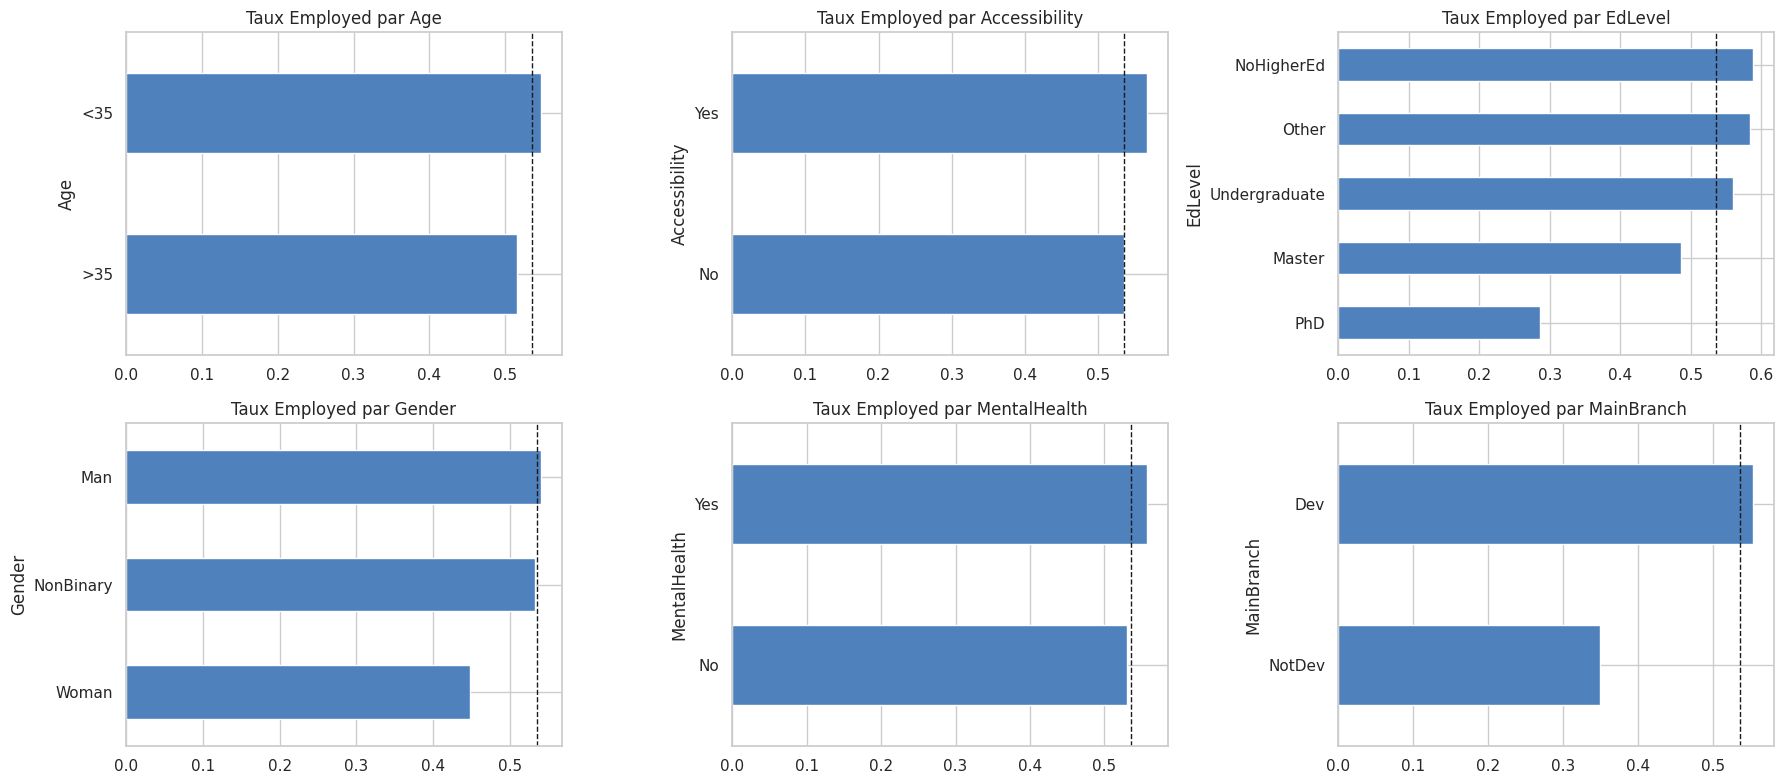

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    df.groupby(c)['Employed'].mean().sort_values().plot.barh(ax=ax, color='#4f81bd')
    ax.axvline(df['Employed'].mean(), color='k', ls='--', lw=1); ax.set_title(f'Taux Employed par {c}')
plt.tight_layout(); plt.show()

## 8. Corrélations (Pearson)

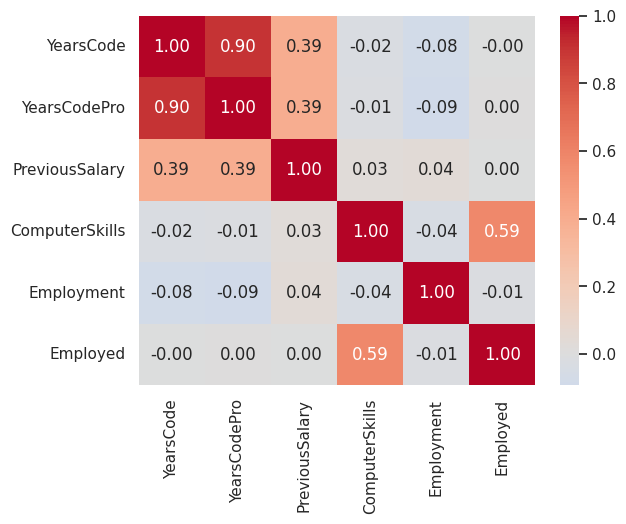

Employment       -0.012142
YearsCode        -0.003756
PreviousSalary    0.000379
YearsCodePro      0.002886
ComputerSkills    0.585545
Name: Employed, dtype: float64

In [11]:
corr = df[num_cols + ['Employment', 'Employed']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()
corr['Employed'].drop('Employed').sort_values()

`ComputerSkills` est de loin la variable la plus corrélée à la cible. `YearsCode` et `YearsCodePro` sont fortement corrélées entre elles (≈ 0,90) : redondance à surveiller (colinéarité).

## 9. Tests statistiques

In [12]:
# Mann-Whitney U : variable numérique vs Employed (distributions non gaussiennes)
rows = []
for c in num_cols:
    a, b = df.loc[df.Employed == 1, c], df.loc[df.Employed == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append((c, a.median(), b.median(), u, p))
pd.DataFrame(rows, columns=['variable', 'médiane Employed=1', 'médiane Employed=0', 'U', 'p-value'])

,variable,médiane Employed=1,médiane Employed=0,U,p-value
0,YearsCode,12.0,12.0,6.821413e+08,1.059684e-04
1,YearsCodePro,7.0,6.0,6.892745e+08,1.863857e-10
2,PreviousSalary,57588.0,57588.0,6.707004e+08,9.049338e-01
3,ComputerSkills,16.0,9.0,1.166783e+09,0.000000e+00


In [13]:
# Chi² d'indépendance + V de Cramér : variable catégorielle vs Employed
rows = []
for c in cat_cols + ['Employment']:
    ct = pd.crosstab(df[c], df['Employed'])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append((c, round(chi2, 1), dof, p, round(v, 3)))
pd.DataFrame(rows, columns=['variable', 'chi2', 'ddl', 'p-value', 'V de Cramér']).sort_values('V de Cramér', ascending=False)

,variable,chi2,ddl,p-value,V de Cramér
2,EdLevel,1073.4,4,4.522245e-231,0.121
5,MainBranch,932.8,1,7.165738e-205,0.113
3,Gender,113.8,2,1.968363e-25,0.039
0,Age,67.1,1,2.549378e-16,0.030
4,MentalHealth,37.2,1,1.065676e-09,0.023
6,Employment,10.8,1,1.040427e-03,0.012
1,Accessibility,8.2,1,4.144514e-03,0.011


Avec 73 000 lignes, presque tout est « significatif » : on lit donc surtout la **taille d'effet** (V de Cramér). `EdLevel` et `MainBranch` pèsent le plus ; `Employment` est quasi sans effet.

## 10. Nettoyage

In [14]:
clean = df.drop(columns='Unnamed: 0').copy()

# 1) Technologies manquantes -> chaîne vide (ComputerSkills vaut alors 0)
clean['HaveWorkedWith'] = clean['HaveWorkedWith'].fillna('').str.strip()

# 2) Incohérence : l'expérience professionnelle ne peut pas dépasser les années de pratique du code
bad = clean['YearsCodePro'] > clean['YearsCode']
clean.loc[bad, 'YearsCodePro'] = clean.loc[bad, 'YearsCode']
print('Lignes corrigées (YearsCodePro > YearsCode) :', bad.sum())

# 3) Espaces parasites sur les catégorielles
for c in cat_cols + ['Country']:
    clean[c] = clean[c].astype(str).str.strip()

clean.drop_duplicates(inplace=True)
print(clean.shape, '| NaN restants :', clean.isna().sum().sum())

Lignes corrigées (YearsCodePro > YearsCode) : 588
(73458, 14) | NaN restants : 0


In [15]:
clean.to_csv('../data/processed/applicants_clean.csv', index=False)
print('Sauvegardé -> data/processed/applicants_clean.csv')

Sauvegardé -> data/processed/applicants_clean.csv
